In [1]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.ticker import AutoMinorLocator
from pathlib import Path

In [ ]:
# --- File paths and sample info ---
DATA_DIR = Path("TS2/Hysterese")

SAMPLE_FILE    = DATA_DIR / "20260717_HYSTERESE_TS2_PH9_300KGY_02.DAT"   # the measured sample
REFERENCE_FILE = DATA_DIR / "2026528_REFERENCE_00001.dat"          # empty sample holder

SAMPLE_MASS_MG     = 7.8      # sample mass [mg]
SAMPLE_MASS_ERR_MG = 0.1      # uncertainty of the mass [mg]

OUTPUT_STEM  = "vsm_mh_ts2_pH9_300kGy_new"       # file name for the saved plot (without extension)

# Background removal method. "interpolate" subtracts the reference
# measurement at the sample's field values.
# or set none
BACKGROUND_METHOD = "interpolate"

# --- Plot options ---
MARKER_SIZE   = 9       # size of the data points
MASS_ERR_BAND = True    # shade an error band from the mass uncertainty
PLOT_RANGE    = None    # None = all data; e.g. (-100, 100) zooms to that field range [kA/m]

# Small zoom window near H = 0 to check whether the loop is open (hysteresis) or not.
SHOW_INSET      = True
INSET_RANGE     = (-30, 30)                 # field range shown in the zoom [kA/m]
INSET_POSITION  = [0.585, 0.07, 0.385, 0.42]  # position and size of the zoom box
INSET_INDICATOR = False  # draw connector lines from the zoom to the main plot

## 1. Physical constants & unit conversions

The PPMS stores the applied field in **Oersted** and the magnetic moment in **emu** (CGS).
We convert to SI:

- Field strength: $1\,\mathrm{Oe} = \dfrac{1000}{4\pi}\,\mathrm{A/m} = \dfrac{1}{4\pi}\,\mathrm{kA/m} \approx 0.0795775\,\mathrm{kA/m}$
- Magnetic moment: $1\,\mathrm{emu} = 10^{-3}\,\mathrm{A\,m^2}$
- Mass magnetization: $\sigma = \dfrac{m_{\mathrm{emu}}\cdot 10^{-3}}{m_{\mathrm{sample}}\,[\mathrm{kg}]}\;\;[\mathrm{A\,m^2/kg}]$

In [3]:
OE_TO_KAM  = 1.0 / (4.0 * np.pi)   # convert field:  Oe  -> kA/m
EMU_TO_AM2 = 1.0e-3                 # convert moment: emu -> A*m^2

mass_kg     = SAMPLE_MASS_MG     * 1.0e-6   # mg -> kg
mass_err_kg = SAMPLE_MASS_ERR_MG * 1.0e-6   # mg -> kg

print(f"Sample mass : {SAMPLE_MASS_MG} +/- {SAMPLE_MASS_ERR_MG} mg "
      f"({100*mass_err_kg/mass_kg:.1f} % relative)")

Sample mass : 7.8 +/- 0.1 mg (1.3 % relative)


In [4]:
# Read one Quantum Design .dat file and return field [Oe], moment [emu], moment error [emu].
def load_vsm(path):
    path = Path(path)
    text = path.read_bytes().decode("latin-1")        # these files are Latin-1 encoded
    lines = text.splitlines()

    # The data starts after the "[Data]" line; the line right after it holds the column names.
    try:
        data_idx = next(i for i, l in enumerate(lines) if l.strip().lower() == "[data]")
    except StopIteration:
        raise ValueError(f"No [Data] section found in {path.name}")

    header = [h.strip() for h in lines[data_idx + 1].split(",")]

    # look up the column index for a given column name
    def col(name):
        try:
            return header.index(name)
        except ValueError:
            raise ValueError(f"Column '{name}' not found in {path.name}. "
                             f"Available: {header[:6]} ...")

    i_field = col("Magnetic Field (Oe)")
    i_mom   = col("Moment (emu)")
    i_err   = col("M. Std. Err. (emu)")

    # go through the data rows and keep only the valid ones
    import csv
    field, moment, merr = [], [], []
    for line in lines[data_idx + 2:]:
        if not line.strip():
            continue
        row = next(csv.reader([line]))
        if row[0].strip():          # text in the first column = a section title -> skip
            continue
        if not row[i_field].strip() or not row[i_mom].strip():
            continue                # skip rows missing field or moment
        field.append(float(row[i_field]))
        moment.append(float(row[i_mom]))
        merr.append(float(row[i_err]) if row[i_err].strip() else np.nan)

    return np.array(field), np.array(moment), np.array(merr)


# load the sample and print a short summary
field_Oe, moment_emu, moment_err_emu = load_vsm(SAMPLE_FILE)
print(f"Sample   : {len(field_Oe)} points, "
      f"field {field_Oe.min():.0f} ... {field_Oe.max():.0f} Oe, "
      f"moment {moment_emu.min():.3e} ... {moment_emu.max():.3e} emu")

# load the reference (empty holder), if one is set
if REFERENCE_FILE is not None:
    ref_field_Oe, ref_moment_emu, _ = load_vsm(REFERENCE_FILE)
    print(f"Reference: {len(ref_field_Oe)} points, "
          f"moment {ref_moment_emu.min():.3e} ... {ref_moment_emu.max():.3e} emu "
          f"({100*np.abs(ref_moment_emu).max()/np.abs(moment_emu).max():.2f} % of sample)")
else:
    ref_field_Oe = ref_moment_emu = None
    print("Reference: none (background subtraction skipped)")

Sample   : 648 points, field -5000 ... 5000 Oe, moment -2.207e-01 ... 2.207e-01 emu
Reference: 905 points, moment -5.581e-05 ... 5.656e-05 emu (0.03 % of sample)


## 3. Subtract the empty-holder background

In [5]:
# Subtract the empty-holder signal from the sample, using the chosen method.
def subtract_background(field, moment, ref_field, ref_moment, method):
    # no reference available -> nothing to subtract
    if method == "none" or ref_field is None:
        return moment.copy(), np.zeros_like(moment)

    elif method == "interpolate":
        # use the reference values directly, matched to the sample's field points
        order = np.argsort(ref_field)                     # np.interp needs sorted x-values
        background = np.interp(field, ref_field[order], ref_moment[order])
    else:
        raise ValueError(f"Unknown BACKGROUND_METHOD: {method!r}")
    return moment - background, background


# run the subtraction and report the largest background value
moment_corr_emu, background_emu = subtract_background(
    field_Oe, moment_emu, ref_field_Oe, ref_moment_emu, BACKGROUND_METHOD
)
print(f"Background method: {BACKGROUND_METHOD!r}; "
      f"max |background| = {np.abs(background_emu).max():.3e} emu")

Background method: 'interpolate'; max |background| = 5.566e-05 emu


## 4. Convert to physical units

Field → kA/m, corrected moment → mass magnetization in Am²/kg. The uncertainty band comes from
the mass error, which dominates ($\sigma$ scales as $1/m_{\mathrm{sample}}$, so the relative
error of $\sigma$ equals the relative error of the mass).

In [6]:
H_kAm  = field_Oe * OE_TO_KAM                              # field in kA/m
sigma  = moment_corr_emu * EMU_TO_AM2 / mass_kg           # mass magnetization in Am^2/kg

# error of sigma, coming from the mass uncertainty
sigma_err = np.abs(sigma) * (mass_err_kg / mass_kg)

print(f"sigma range: {sigma.min():.2f} ... {sigma.max():.2f} Am^2/kg")
print(f"field range: {H_kAm.min():.1f} ... {H_kAm.max():.1f} kA/m")

sigma range: -28.31 ... 28.30 Am^2/kg
field range: -397.9 ... 397.9 kA/m


In [7]:
# --- Anhysteretic curve, coercivity and remanence ---
# A hysteresis loop is two-valued (two branches); the Langevin function describes the
# single-valued, reversible (anhysteretic) magnetization. We average the ascending and
# descending branch at each field. Since the two branches were sampled at different fields,
# one branch is linearly interpolated onto the other's field values before averaging. The
# curve is evaluated at the measured branch fields (no invented grid) and then symmetrized
# about H = 0 to enforce sigma(-H) = -sigma(H).
def anhysteretic_curve(H, sig):
    sgn = np.sign(np.diff(H))
    turns = [0]
    for i in range(1, len(sgn)):
        if sgn[i] != 0 and sgn[i] != sgn[i - 1]:
            turns.append(i)                       # a field turning point starts a new branch
    turns.append(len(H) - 1)
    segs = [(turns[k], turns[k + 1]) for k in range(len(turns) - 1)]
    dseg = max((s for s in segs if H[s[0]] > H[s[1]]), key=lambda s: s[1] - s[0])  # descending
    useg = max((s for s in segs if H[s[0]] < H[s[1]]), key=lambda s: s[1] - s[0])  # ascending
    def srt(seg):
        a, b = seg
        o = np.argsort(H[a:b + 1])
        return H[a:b + 1][o], sig[a:b + 1][o]     # branch sorted by field
    hd, sd = srt(dseg)
    hu, su = srt(useg)
    Hf = np.sort(np.concatenate([hd, hu]))        # all measured branch fields
    lo, hi = max(hd.min(), hu.min()), min(hd.max(), hu.max())
    Hf = Hf[(Hf >= lo) & (Hf <= hi)]              # keep the range both branches cover
    s_anh = 0.5 * (np.interp(Hf, hd, sd) + np.interp(Hf, hu, su))   # average -> removes hysteresis
    s_sym = 0.5 * (s_anh - np.interp(-Hf, Hf, s_anh))              # enforce odd symmetry
    Hc = 0.5 * (abs(np.interp(0.0, sd, hd)) + abs(np.interp(0.0, su, hu)))  # |H| at sigma = 0
    sr = 0.5 * (abs(np.interp(0.0, hd, sd)) + abs(np.interp(0.0, hu, su)))  # |sigma| at H = 0
    return Hf, s_sym, Hc, sr

H_anh, sigma_anh, Hc, sigma_r = anhysteretic_curve(H_kAm, sigma)
print(f"Anhysteretic curve: {len(H_anh)} points (measured branch fields)")
print(f"Coercive field   Hc      = {Hc:.3f} kA/m = {Hc / OE_TO_KAM:.1f} Oe")
print(f"Remanence        sigma_r = {sigma_r:.3f} Am^2/kg "
      f"({100 * sigma_r / np.max(np.abs(sigma)):.2f} % of sigma_max)")

Anhysteretic curve: 375 points (measured branch fields)
Coercive field   Hc      = 1.201 kA/m = 15.1 Oe
Remanence        sigma_r = 1.041 Am^2/kg (3.68 % of sigma_max)


## 5. Matplotlib style

In [8]:
# Global plot style: fonts, ticks and sizes.
plt.rcParams.update({
    "font.family":       "serif",
    "font.serif":        ["DejaVu Serif", "Times New Roman", "Times"],
    "font.size":         11,
    "axes.labelsize":    12,
    "axes.titlesize":    12,
    "xtick.labelsize":   10,
    "ytick.labelsize":   10,
    "legend.fontsize":   10,
    "axes.linewidth":    0.9,
    "xtick.direction":   "in",
    "ytick.direction":   "in",
    "xtick.top":         True,
    "ytick.right":       True,
    "xtick.major.size":  5,
    "ytick.major.size":  5,
    "xtick.minor.size":  2.5,
    "ytick.minor.size":  2.5,
    "xtick.major.width": 0.9,
    "ytick.major.width": 0.9,
    "xtick.minor.width": 0.7,
    "ytick.minor.width": 0.7,
    "mathtext.fontset":  "dejavuserif",
})

## 6. Plot the hysteresis loop

Langevin + high-field fit: sigma_s(core) = 22.66 +/- 0.296 Am^2/kg, d = 10.35 +/- 0.16 nm, chi_hf = 1.700e-05 +/- 2.9e-07 m^3/kg, R^2 = 0.9998
At H_max = 398 kA/m: core = 22.01 Am^2/kg, linear = 6.77 Am^2/kg (24 % of total), sum = 28.78 Am^2/kg
Saved: vsm_mh_ts2_pH9_300kGy_neu.pdf


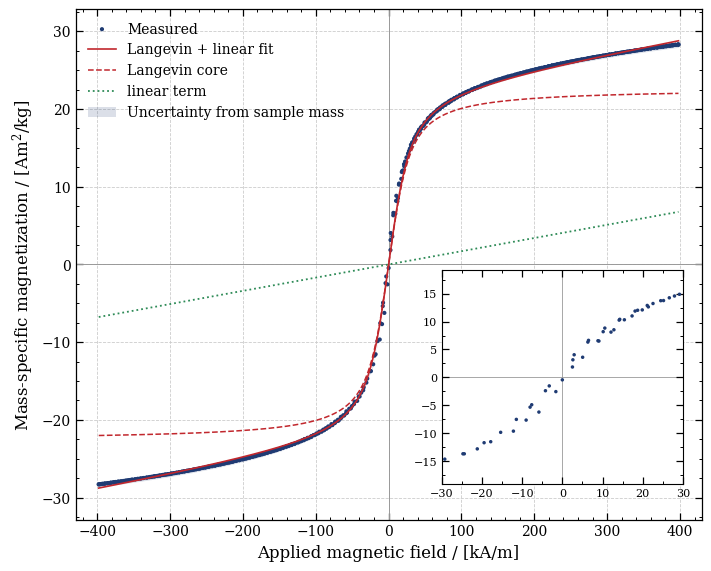

In [9]:
from scipy.optimize import curve_fit

# --- Langevin fit settings ---
TEMPERATURE_K = 300.0      # temperature during the measurement [K]
SIGMA_S_BULK  = 96.0       # bulk magnetite saturation [Am^2/kg] (lower bound of literature range)
RHO_FE3O4     = 5.18e3     # density of bulk magnetite [kg/m^3]

MU0  = 4.0e-7 * np.pi              # vacuum permeability
KB   = 1.380649e-23                # Boltzmann constant
M_SB = RHO_FE3O4 * SIGMA_S_BULK    # bulk saturation magnetization per volume [A/m]

# Langevin function L(a) = coth(a) - 1/a (with a safe approximation for very small a).
def _langevin(a):
    out = np.empty_like(a, dtype=float)
    small = np.abs(a) < 1e-4
    out[small] = a[small] / 3.0          # for tiny a, L(a) ~ a/3 (avoids dividing by zero)
    aa = a[~small]
    out[~small] = 1.0 / np.tanh(aa) - 1.0 / aa
    return out

# Core model: mass magnetization vs. field for superparamagnetic particles of diameter d.
def sigma_langevin(H_Am, sigma_s_core, d):
    alpha = MU0 * M_SB * np.pi * d**3 * H_Am / (6.0 * KB * TEMPERATURE_K)
    return sigma_s_core * _langevin(alpha)

# Full model: Langevin core plus an empirical linear high-field term. chi_hf [m^3/kg]
# is the high-field susceptibility describing the non-saturating contribution (usually
# attributed to the disordered surface shell); it is added to the saturating core, so
# that sigma_s_core and d describe the ordered core once the linear part is removed.
def sigma_model(H_Am, sigma_s_core, d, chi_hf):
    return sigma_langevin(H_Am, sigma_s_core, d) + chi_hf * H_Am

# --- Langevin + linear high-field fit -------------------------------------
# Performed on the ANHYSTERETIC curve (field in A/m). To make the result independent
# of the arbitrary vertical scale set by the sample mass, the amplitude is normalized
# to 1 before fitting: the diameter d is fixed by the SHAPE of the curve alone, while
# sigma_s_core and chi_hf are recovered afterwards by multiplying back by s_norm.
s_norm   = np.max(np.abs(sigma_anh))
H_max_Am = np.abs(H_anh).max() * 1e3       # maximum field [A/m]

popt_n, pcov_n = curve_fit(
    lambda H, frac, d, chi_n: sigma_langevin(H, frac, d) + chi_n * H,
    H_anh * 1e3, sigma_anh / s_norm,
    p0=[0.9, 8.0e-9, 0.3 / H_max_Am],
    bounds=([0.0, 1e-10, 0.0], [np.inf, 1e-6, np.inf]),
    x_scale=[1.0, 1e-9, 1.0 / H_max_Am], maxfev=40000)

frac_n, d_fit, chi_n = popt_n
perr_n = np.sqrt(np.diag(pcov_n))
sigma_s_fit = s_norm * frac_n          # back to physical units (d needs no conversion)
chi_hf_fit  = s_norm * chi_n
popt = np.array([sigma_s_fit, d_fit, chi_hf_fit])
perr = np.array([s_norm * perr_n[0], perr_n[1], s_norm * perr_n[2]])   # fit errors (one standard deviation)

# total uncertainty of sigma_s and chi_hf: fit error and mass-scale error added in quadrature
sigma_s_err_total = np.sqrt(perr[0]**2 + (sigma_s_fit * mass_err_kg / mass_kg)**2)
d_err_total       = np.sqrt(perr[1]**2 + (d_fit * (4.0/96.0)/3.0)**2)
chi_hf_err_total  = np.sqrt(perr[2]**2 + (chi_hf_fit * mass_err_kg / mass_kg)**2)
res = sigma_anh - sigma_model(H_anh * 1e3, *popt)
r2 = 1.0 - np.sum(res**2) / np.sum((sigma_anh - sigma_anh.mean())**2)    # goodness of fit
print(f"Langevin + high-field fit: sigma_s(core) = {sigma_s_fit:.2f} +/- {sigma_s_err_total:.3f} Am^2/kg, "
      f"d = {d_fit*1e9:.2f} +/- {d_err_total*1e9:.2f} nm, "
      f"chi_hf = {chi_hf_fit:.3e} +/- {chi_hf_err_total:.1e} m^3/kg, R^2 = {r2:.4f}")

# decompose the fitted curve into core (Langevin) and linear high-field parts at max field
core_at_max  = sigma_langevin(np.array([H_max_Am]), sigma_s_fit, d_fit)[0]
hf_at_max    = chi_hf_fit * H_max_Am                                 # linear high-field term [Am^2/kg]
total_at_max = core_at_max + hf_at_max
print(f"At H_max = {H_max_Am/1e3:.0f} kA/m: "
      f"core = {core_at_max:.2f} Am^2/kg, "
      f"linear = {hf_at_max:.2f} Am^2/kg "
      f"({100*hf_at_max/total_at_max:.0f} % of total), "
      f"sum = {total_at_max:.2f} Am^2/kg")

# pick which field range to plot (raw loop)
if PLOT_RANGE is None:
    m = np.ones_like(H_kAm, dtype=bool)
else:
    m = (H_kAm >= PLOT_RANGE[0]) & (H_kAm <= PLOT_RANGE[1])
x, y, yerr = H_kAm[m], sigma[m], sigma_err[m]

# set up the figure with a grid and zero-lines
fig, ax = plt.subplots(figsize=(7.0, 5.6), constrained_layout=True)
ax.set_axisbelow(True)
ax.grid(True, which="major", linestyle="--", linewidth=0.6, color="0.8")
ax.axhline(0.0, color="0.6", linewidth=0.7, zorder=1)
ax.axvline(0.0, color="0.6", linewidth=0.7, zorder=1)

# the measured data points (raw loop)
ax.scatter(x, y, s=MARKER_SIZE, color="#1f3b73", edgecolors="none",
           label="Measured", zorder=3)

# the fitted model curve (drawn smoothly over the field range)
H_dense = np.linspace(x.min(), x.max(), 600)
ax.plot(H_dense, sigma_model(H_dense * 1e3, *popt),
        color="#c1272d", linewidth=1.2, zorder=5, label="Langevin + linear fit")

# the two fit components shown separately: Langevin core and linear high-field term
ax.plot(H_dense, sigma_langevin(H_dense * 1e3, sigma_s_fit, d_fit),
        color="#c1272d", linewidth=1.1, linestyle="--", zorder=4, label="Langevin core")
ax.plot(H_dense, chi_hf_fit * (H_dense * 1e3),
        color="#2e8b57", linewidth=1.3, linestyle=":", zorder=4,
        label=r"linear term")

# error band from the mass uncertainty (drawn behind the points)
if MASS_ERR_BAND:
    order = np.argsort(x)
    ax.fill_between(x[order], (y - yerr)[order], (y + yerr)[order],
                    color="#1f3b73", alpha=0.16, linewidth=0, zorder=2,
                    label="Uncertainty from sample mass")

ax.set_xlabel(r"Applied magnetic field / [kA/m]")
ax.set_ylabel(r"Mass-specific magnetization / [Am$^2$/kg]")
xpad = 0.04 * (x.max() - x.min())
ypad = 0.08 * (y.max() - y.min())
ax.set_xlim(x.min() - xpad, x.max() + xpad)
ax.set_ylim(y.min() - ypad, y.max() + ypad)
ax.xaxis.set_minor_locator(AutoMinorLocator(5))
ax.yaxis.set_minor_locator(AutoMinorLocator(4))
ax.legend(frameon=False, loc="upper left")

# small zoom window near H = 0 (measured points only, no fit line)
if SHOW_INSET:
    axins = ax.inset_axes(INSET_POSITION)
    sel = (x >= INSET_RANGE[0]) & (x <= INSET_RANGE[1])
    axins.axhline(0.0, color="0.6", linewidth=0.6, zorder=0)
    axins.axvline(0.0, color="0.6", linewidth=0.6, zorder=0)
    axins.scatter(x[sel], y[sel], s=max(MARKER_SIZE * 0.7, 4),
                  color="#1f3b73", edgecolors="none", zorder=3)
    axins.set_xlim(*INSET_RANGE)
    yz = y[sel]
    if yz.size:
        pad = 0.15 * (yz.max() - yz.min() or 1.0)
        axins.set_ylim(yz.min() - pad, yz.max() + pad)
    axins.tick_params(labelsize=8, direction="in", top=True, right=True)
    axins.xaxis.set_minor_locator(AutoMinorLocator(2))
    axins.yaxis.set_minor_locator(AutoMinorLocator(2))
    for spine in axins.spines.values():
        spine.set_linewidth(0.8)
    if INSET_INDICATOR:
        ax.indicate_inset_zoom(axins, edgecolor="0.4", linewidth=0.8, alpha=0.8)

# save the plot as a PDF and show it
fig.savefig(f"{OUTPUT_STEM}.pdf")
print(f"Saved: {OUTPUT_STEM}.pdf")
plt.show()

In [ ]:
import csv

ZFC_FC_DIR  = Path("TS2/ZFC-FC")                 # folder with the ZFC/FC files
ZFC_FC_STEM = "20260717_PH9_150KGY"      # common part of the file names
ZFC_FC_FIELDS_OE = [20, 50, 100, 200]            # measuring fields [Oe]
ZFC_TAG, FC_TAG  = "ZFC", "FC"                   # file-name tags

ZFC_FC_MASS_MG = 8        # <-- dry mass of sample [mg]; scales the y-axis only
ZFC_FC_SMOOTH  = 1          # moving-average window for display (1 = raw; e.g. 5 = lightly smoothed)
ZFC_FC_OUTPUT  = "vsm_zfc_fc_ts2_pH9_150kGy"         # output PDF name (without extension)

# Read a Quantum Design M(T) file -> temperature [K], moment [emu], sorted by T.
def load_mt(path):
    path  = Path(path)
    lines = path.read_bytes().decode("latin-1").splitlines()
    try:
        di = next(i for i, l in enumerate(lines) if l.strip().lower() == "[data]")
    except StopIteration:
        raise ValueError(f"No [Data] section found in {path.name}")
    header = [h.strip() for h in lines[di + 1].split(",")]
    iT, iM = header.index("Temperature (K)"), header.index("Moment (emu)")
    T, M = [], []
    for line in lines[di + 2:]:
        if not line.strip():
            continue
        row = next(csv.reader([line]))
        if row[0].strip():                       # comment/section row -> skip
            continue
        if not row[iT].strip() or not row[iM].strip():
            continue                             # skip rows missing temperature or moment
        T.append(float(row[iT])); M.append(float(row[iM]))
    T, M = np.array(T), np.array(M)
    o = np.argsort(T)
    return T[o], M[o]

def _smooth(y, k):
    if k <= 1 or k >= len(y):
        return y
    k = k | 1                                    # force odd window
    return np.convolve(y, np.ones(k) / k, mode="same")

# load each field and convert moment -> mass magnetization sigma [Am^2/kg]
zfc_fc_mass_kg = ZFC_FC_MASS_MG * 1e-6
zfc_fc = {}
for Hset in ZFC_FC_FIELDS_OE:
    Tz, Mz = load_mt(ZFC_FC_DIR / f"{ZFC_FC_STEM}_{ZFC_TAG}_{Hset}_OE.DAT")
    Tf, Mf = load_mt(ZFC_FC_DIR / f"{ZFC_FC_STEM}_{FC_TAG}_{Hset}_OE.DAT")
    sz = _smooth(Mz * EMU_TO_AM2 / zfc_fc_mass_kg, ZFC_FC_SMOOTH)
    sf = _smooth(Mf * EMU_TO_AM2 / zfc_fc_mass_kg, ZFC_FC_SMOOTH)
    zfc_fc[Hset] = (Tz, sz, Tf, sf)
    print(f"{Hset:4d} Oe: ZFC {len(Tz)} pts, FC {len(Tf)} pts ({Tz.min():.0f}-{Tz.max():.0f} K)")

  20 Oe: ZFC 557 pts, FC 547 pts (4-300 K)
  50 Oe: ZFC 560 pts, FC 550 pts (4-300 K)
 100 Oe: ZFC 560 pts, FC 546 pts (4-300 K)
 200 Oe: ZFC 557 pts, FC 550 pts (4-300 K)


Saved: vsm_zfc_fc_ts2_pH9_150kGy.pdf


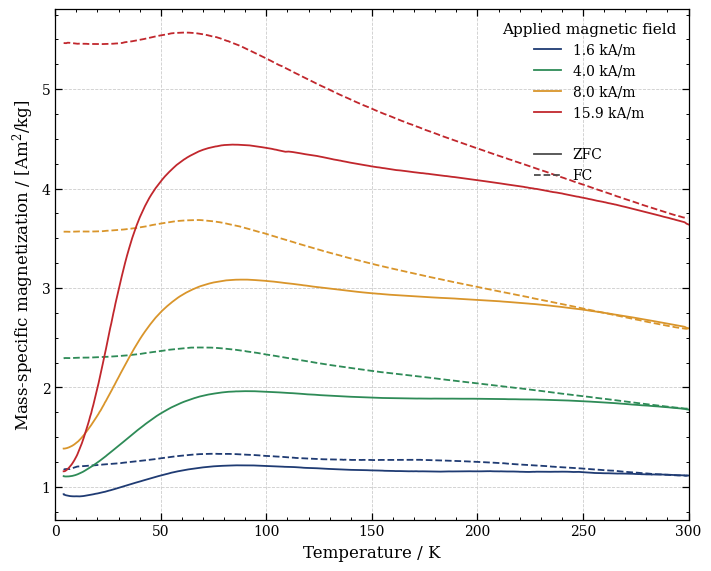

In [ ]:
from matplotlib.lines import Line2D

fig, ax = plt.subplots(figsize=(7.0, 5.6), constrained_layout=True)
ax.set_axisbelow(True)
ax.grid(True, which="major", linestyle="--", linewidth=0.6, color="0.8")

colors = ["#1f3b73", "#2e8b57", "#d9952b", "#c1272d"]   # one colour per field (low -> high)
for (Hset, (Tz, sz, Tf, sf)), c in zip(zfc_fc.items(), colors):
    ax.plot(Tz, sz, "-",  color=c, linewidth=1.3)        # ZFC: solid
    ax.plot(Tf, sf, "--", color=c, linewidth=1.3)        # FC : dashed

ax.set_xlabel(r"Temperature / K")
ax.set_ylabel(r"Mass-specific magnetization / [Am$^2$/kg]")
ax.set_xlim(0, 300)
ax.xaxis.set_minor_locator(AutoMinorLocator(5))
ax.yaxis.set_minor_locator(AutoMinorLocator(4))

# two-part legend: colour = field, line style = ZFC vs FC
field_handles = [Line2D([], [], color=c, lw=1.3, label=f"{H * OE_TO_KAM:.1f} kA/m") #label=f"{H} Oe")
                 for H, c in zip(ZFC_FC_FIELDS_OE, colors)]
style_handles = [Line2D([], [], color="0.3", lw=1.3, ls="-",  label="ZFC"),
                 Line2D([], [], color="0.3", lw=1.3, ls="--", label="FC")]
spacer = [Line2D([], [], linestyle="none", label=" ")]   # blank entry for spacing
ax.legend(handles=field_handles + spacer + style_handles, frameon=False,
          loc="upper right", title="Applied magnetic field")

fig.savefig(f"{ZFC_FC_OUTPUT}.pdf")
print(f"Saved: {ZFC_FC_OUTPUT}.pdf")
plt.show()